# Plot one field

Uses full paths, so this notebook works from any folder. Restart the kernel after editing `score_deks.py`, because Python keeps the first import in memory. Cell 1 prints which `score_deks.py` it loaded, and it should be the one in the project folder.

The A file lists areas only, not positions, so they are placed on the cells by assuming marker order. That only works when our kept count equals the A count; otherwise the figure says so and shows distributions instead. A low r in the third panel means the counts match but the areas do not line up (as in fields 2.3 and 7.3).

In [2]:
%matplotlib inline
import sys
from pathlib import Path

PROJECT = Path(r"C:\2026_ECD_CV_HEX_CCD_Calculation")
sys.path.insert(0, str(PROJECT))      # use the project's score_deks.py, not an old copy elsewhere

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import cm, colors
from scipy.spatial import ConvexHull

import score_deks as sd
print("using", sd.__file__)

ROOT = PROJECT / "SAMPLE - DEKS-EYEBANK" / "Reader1"
UM = 0.768                       # um per pixel
sd.MIN_PEELED = 99               # extra peel filter off, as in the current settings

using C:\2026_ECD_CV_HEX_CCD_Calculation\score_deks.py


In [3]:
def plot_field(image, field, save=False):
    """C markers with the P box, A-file areas on the cells, and instrument vs our area."""
    hit = [(a, c) for img, k, a, c in sd.frames(ROOT) if img == str(image) and k == str(field)]
    if not hit:
        raise ValueError(f"No A and C files found for image {image}, field {field}.")
    a_path, c_path = hit[0]
    areas, sides, _ = sd.read_A(a_path)
    pts, _, _ = sd.read_C(c_path)
    p_path = c_path.with_name(f"P{field}.dat")
    box = np.array(p_path.read_text().split(), float)[:4] if p_path.exists() else None

    cl = sd.power_cells(pts, np.zeros(len(pts)))
    keep = sd.keep_cells(pts, cl)
    ours = np.array([sd.area(cl[i]) for i in keep]) * UM ** 2
    aligned = len(keep) == len(areas)
    r = float(np.corrcoef(ours, areas)[0, 1]) if aligned else float("nan")

    fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))

    # 1. C file: markers, P box, hull
    ax = axs[0]
    if box is not None:
        x, y, w, h = box
        ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="blue", facecolor="none"))
        ax.text(x + 4, y + 16, f"P{field}  ({x:.0f}, {y:.0f})", color="red", fontsize=10)
        ax.set_xlim(x - 20, x + w + 20)
        ax.set_ylim(y - 20, y + h + 20)
    hv = pts[ConvexHull(pts).vertices]
    ax.plot(*np.vstack([hv, hv[:1]]).T, color="green", linewidth=1)
    kept = np.zeros(len(pts), bool)
    kept[keep] = True
    ax.scatter(*pts[~kept].T, s=14, facecolors="none", edgecolors="gray")
    ax.scatter(*pts[kept].T, s=14, color="black")
    ax.set_title(f"C file: {len(pts)} markers, {len(keep)} kept (filled), rest peeled (hollow)")

    # 2. cells coloured by the A-file area (or by our own area if A cannot be placed)
    ax = axs[1]
    vals = areas if aligned else ours
    norm = colors.Normalize(vals.min(), vals.max())
    for i, v in zip(keep, vals):
        ax.add_patch(patches.Polygon(cl[i], closed=True, facecolor=cm.viridis(norm(v)),
                                     edgecolor="white", linewidth=0.6))
    corners = np.vstack([cl[i] for i in keep])
    ax.set_xlim(corners[:, 0].min() - 10, corners[:, 0].max() + 10)
    ax.set_ylim(corners[:, 1].min() - 10, corners[:, 1].max() + 10)
    fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cm.viridis), ax=ax, shrink=0.8,
                 label="instrument area (um2)" if aligned else "our Voronoi area (um2)")
    ax.set_title("A file areas on our cells" if aligned
                 else f"A count {len(areas)} differs from our kept count {len(keep)}: showing our own areas")

    # 3. instrument vs our area
    ax = axs[2]
    if aligned:
        ax.scatter(ours, areas, s=14)
        lim = [min(ours.min(), areas.min()), max(ours.max(), areas.max())]
        ax.plot(lim, lim, "--", color="gray")
        ax.set_xlabel("our Voronoi area (um2)")
        ax.set_ylabel("instrument area (um2)")
        note = "  (low r: the A file may not line up with these cells)" if r < 0.7 else ""
        ax.set_title(f"r = {r:.2f}, slope = {np.polyfit(ours, areas, 1)[0]:.2f}{note}")
    else:
        bins = np.linspace(min(ours.min(), areas.min()), max(ours.max(), areas.max()), 20)
        ax.hist(areas, bins=bins, alpha=0.6, label=f"instrument (n={len(areas)})")
        ax.hist(ours, bins=bins, alpha=0.6, label=f"ours (n={len(ours)})")
        ax.set_xlabel("cell area (um2)")
        ax.legend()
        ax.set_title("Area distributions (cells cannot be matched one to one)")

    for ax in axs[:2]:
        ax.set_aspect("equal")
        ax.invert_yaxis()                  # image coordinates: y grows downward
    fig.suptitle(f"Image {image}, field {field}")
    fig.tight_layout()
    if save:
        fig.savefig(f"field_{image}_{field}.png", dpi=110)
    plt.show()
    print(f"image {image}, field {field}: aligned = {aligned}, r = {r:.2f}")

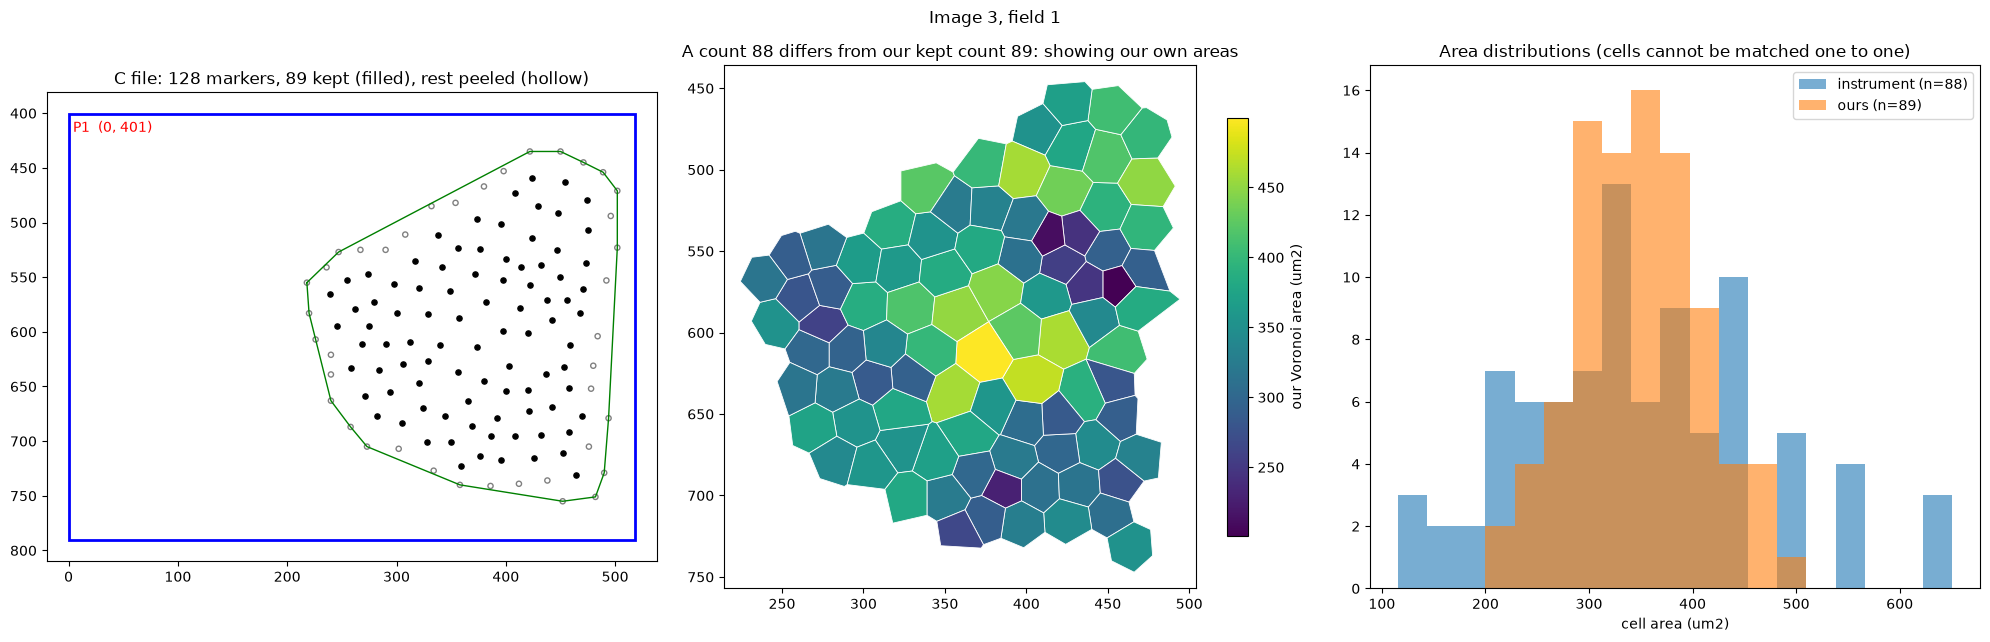

image 3, field 1: aligned = False, r = nan


In [4]:
plot_field(3, 1)

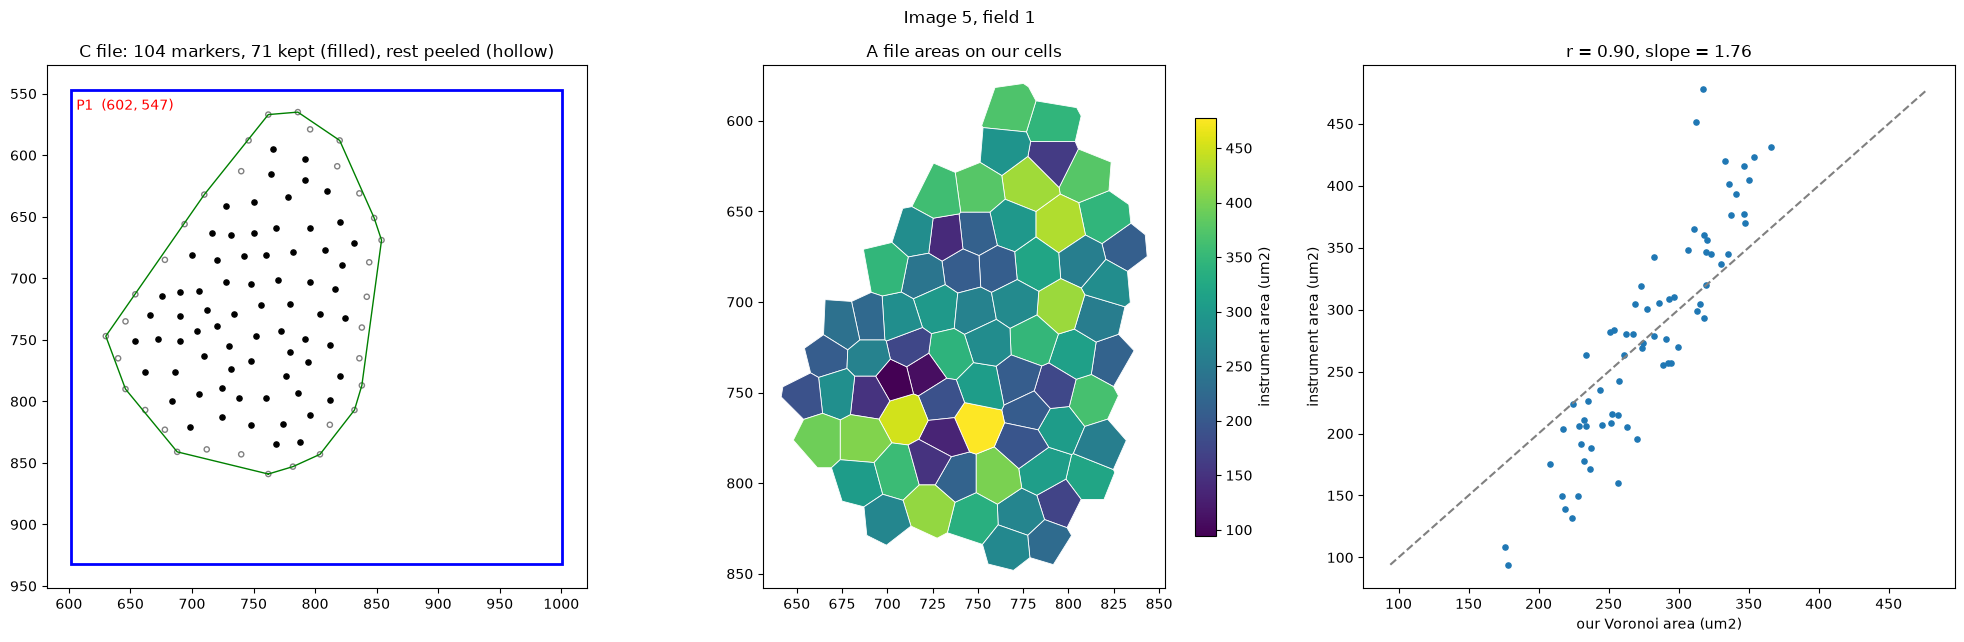

image 5, field 1: aligned = True, r = 0.90


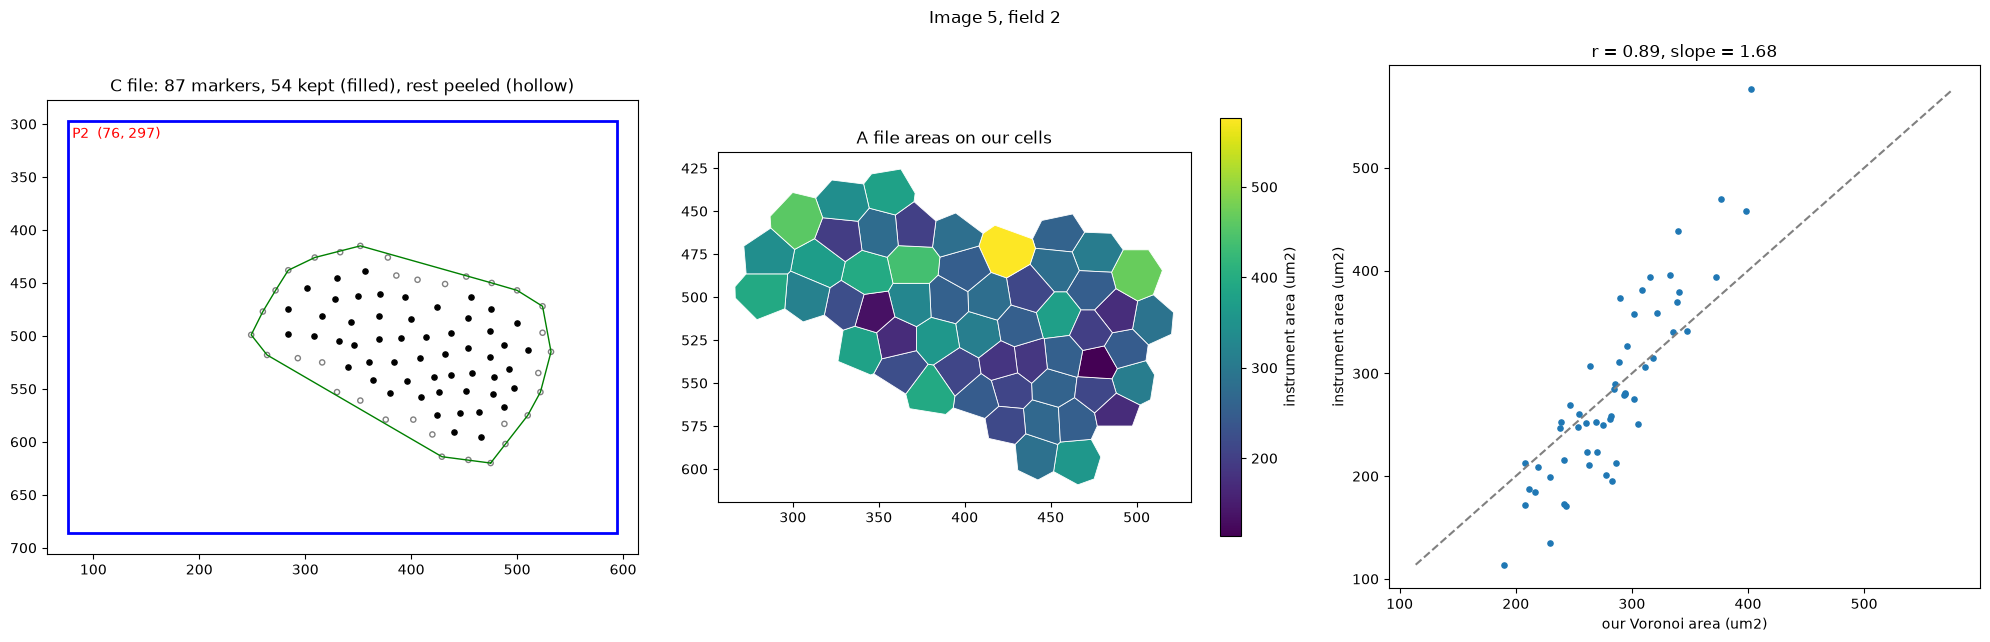

image 5, field 2: aligned = True, r = 0.89


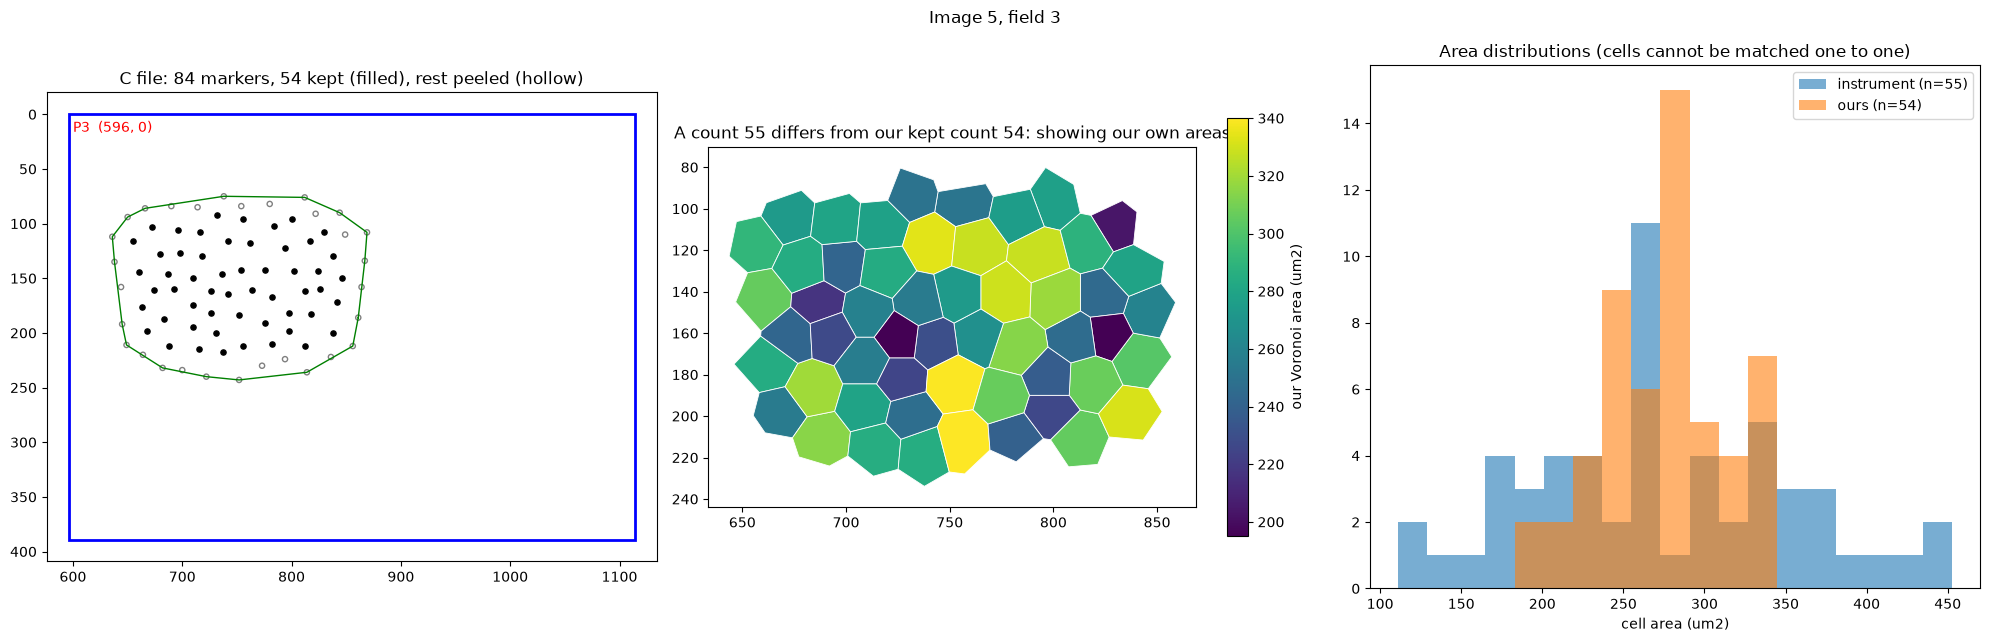

image 5, field 3: aligned = False, r = nan


In [5]:
# several fields of one image, or save a PNG with save=True
for f in (1, 2, 3):
    plot_field(5, f)